# 1. MC 프라이서 — 현행 방법론

이론가(MC)를 만드는 **현행 방법론 한 벌**을 정의하고, 재현성과 공정가 대비 오차까지 한 장에서 확인한다.

| 입력 | 현행 정의 | 구현 |
|---|---|---|
| 변동성 | 6개월(120 영업일) EWMA, 감쇠 λ = 0.99 | `module.features.vol_ewma_lam` |
| 상관 | 6개월(KRX 영업일 120일) 창, **쌍별** Pearson | `module.features.corr_bd` |
| 시뮬레이션 | 일별 GBM, 기하 worst-of | `module.mc_engine.mc_daily_t` |
| 할인 | CD 91일 + IRS par 부트스트랩 제로커브 | `module.curve` |
| 배당 | 이산배당 (지수는 추종 ETF 프록시) | `module.dividend` |

세 가지를 미리 못박는다.

- **경로 수.** 저장된 `mc_B` 열은 **40,000 경로**로 산출됐다. 방법론 목표는 10만이며, 아래 3절에서 두 경로 수의
  몬테카를로 잡음을 직접 재서 그 차이가 무엇을 의미하는지 보인다.
- **`features.vol_ewma` 는 현행 정의가 아니다.** 그건 `span=120`(λ ≈ 0.9835)인 자문안 정의다. 현행은 λ = 0.99.
- **`features.corr180` 도 현행 정의가 아니다.** 3시장 공통 거래일로 자르면 창이 6.2~6.9개월로 늘어난다.
  현행은 KRX 영업일 120일 창에서 쌍별로 센다.

인과성: 모든 입력은 발행일 **이전**에 공시된 값만 쓴다.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from util import file_manager as fm, plot as _plot      # import 만으로 dpi400·투명·PPT 밴드
from module import features as F, curve as CV, dividend as DV, mc_engine as ME
from module.schedule import LZ_BARR_NEUTRAL
from module.mc import load_market

FACE = 10000
NSAMPLE = 40                                            # 재현·잡음 대조 표본
C_REF, C_NEW = "#e07a5f", "#1f6f9c"

df = pd.read_parquet(fm.DATA / "els3_dataset.parquet").sort_values("isu_ord").reset_index(drop=True)
VAR = pd.read_parquet(fm.CACHE / "mcvar" / "mc_variants.parquet").set_index("item")
mk = load_market()
RET = mk["RET"]
KBD = RET["^KS200"].dropna().index                      # KRX 거래일 달력
print(f"상품 {len(df):,} | 저장된 변형 {VAR.shape} | 수익률 시계열 {len(RET)}종")

상품 58,790 | 저장된 변형 (58790, 31) | 수익률 시계열 46종


## 1-1. 시장입력 조립

상품 하나의 발행일 기준으로 네 입력을 만든다. 이 함수가 현행 방법론의 **유일한 정의**다 —
종전에는 같은 조립이 `module/mc.py`, `module/build_source.py`, `tools/mc_discrete_div.py`,
`5_MC_implied_vol.ipynb` 네 곳에 흩어져 있었다.

In [2]:
def market_for(row):
    """발행일 기준 (변동성 3, 상관 3x3, 제로커브 콜러블, 이산배당 N x 3). 못 만들면 None."""
    dt = pd.Timestamp.fromordinal(int(row["isu_ord"]))
    tks = [row["udl1"], row["udl2"], row["udl3"]]
    rets = [RET.get(t) for t in tks]
    if any(r is None for r in rets):
        return None
    sig = [F.vol_ewma_lam(r, dt) for r in rets]         # 6개월 EWMA, lambda=0.99
    corr, _ = F.corr_bd(rets, dt, KBD)                  # 6개월 영업일 창, 쌍별
    dz = CV.zero_from_date(dt)                          # CD + IRS 부트스트랩
    if corr is None or dz is None or np.isnan(sig).any():
        return None
    divlog, qc, nev, _ = DV.build_div(tks, dt, float(row["tenor"]))
    return dict(dt=dt, tks=tks, sig=sig, corr=corr, dz=dz, divlog=divlog, qcont=qc, ndiv=nev)


def contract_for(row):
    """계약 조항 (행사가 · 지급률 · 리자드 · 배리어 · 쿠폰 · 만기)."""
    n = int(row["nobs"])
    lzb = [float(row[f"lz_barr_{j}"]) if row[f"lz_barr_{j}"] < LZ_BARR_NEUTRAL else np.nan
           for j in range(n)]
    return dict(B=float(row["B"]), strikes=[float(row[f"strk_{j}"]) for j in range(n)],
                ten=float(row["tenor"]), c=float(row["coupon"]),
                pmts=[float(row[f"pmt_{j}"]) for j in range(n)],
                lz_barr=lzb, lz_pmt=[float(row[f"lz_pmt_{j}"]) for j in range(n)])


def price(row, n_path, seed=None):
    """현행 방법론으로 상품 하나 가격. 공통난수 기본값은 상품 고유 mc_seed."""
    m = market_for(row)
    if m is None:
        return np.nan
    k = contract_for(row)
    return float(ME.mc_daily_t(m["sig"], m["corr"], m["dz"], k["B"], k["strikes"], k["ten"],
                               n=n_path, seed=int(row["mc_seed"]) if seed is None else seed,
                               c=k["c"], pmts=k["pmts"], lz_barr=k["lz_barr"], lz_pmt=k["lz_pmt"],
                               divlog=m["divlog"]))


rng = np.random.default_rng(0)
pick = rng.choice(len(df), NSAMPLE, replace=False)
S = df.iloc[pick].copy()
ex = market_for(df.iloc[pick[0]])
print("예시 상품", df.iloc[pick[0]]["item"], "발행", ex["dt"].date())
print("  기초자산      ", ex["tks"])
print("  변동성 (연율) ", np.round(ex["sig"], 4))
print("  상관          ", np.round(ex["corr"][np.triu_indices(3, 1)], 4))
print("  제로금리 1/3/5Y", np.round(ex["dz"](np.array([1.0, 3.0, 5.0])), 5))
print("  배당 이벤트   ", ex["ndiv"], "건 | 연환산 q", np.round(ex["qcont"], 4))

예시 상품 20230914000366_3248 발행 2023-10-11
  기초자산       ['^GSPC', '^N225', '^STOXX50E']
  변동성 (연율)  [0.1171 0.1668 0.1418]
  상관           [0.2279 0.5134 0.3816]
  제로금리 1/3/5Y [0.03937 0.03951 0.03956]
  배당 이벤트    27 건 | 연환산 q [0.0156 0.0172 0.0307]


## 1-2. 재현 검증 — 저장된 `mc_B` 와 대조

`data/cache/mcvar/mc_variants.parquet` 의 `mc_B` 열이 현행 방법론으로 산출된 이론가다.
같은 경로 수(40,000)·같은 공통난수로 다시 매기면 **비트 단위로 같아야** 한다.

종전에는 이 계산이 `tools/mc_discrete_div.py` 의 엔진 복사본으로만 가능했다.
`mc_engine` 에 커브 콜러블·배당 드리프트를 파라미터로 올려 포크 없이 재현된다.

In [3]:
ref = VAR.loc[S["item"].values, "mc_B"].values
got = np.array([price(S.iloc[i], n_path=40_000) for i in range(len(S))])
ok = np.isfinite(ref) & np.isfinite(got)
gap = np.abs(got[ok] - ref[ok]) * FACE
print(f"대조 {ok.sum()}건 | 최대 차이 {gap.max():.2e}원 | 평균 {gap.mean():.2e}원")
print("결과:", "일치 — 추적 패키지만으로 현행 방법론이 재현된다" if gap.max() < 1e-6
      else f"불일치 — 최대 {gap.max():.4f}원, 입력 정의를 다시 확인할 것")

대조 40건 | 최대 차이 0.00e+00원 | 평균 0.00e+00원
결과: 일치 — 추적 패키지만으로 현행 방법론이 재현된다


## 1-3. 경로 수와 몬테카를로 잡음

경로 수는 **정확도가 아니라 잡음**을 정한다. 같은 상품을 서로 다른 난수로 두 번 매겨
그 차이에서 표준오차를 역산한다 (두 독립 추정의 차이 표준편차 ÷ √2).

이 숫자가 중요한 이유: 대리모형의 MAE 와 비교해 **라벨 잡음이 성능 상한의 얼마를 차지하는지** 알려준다.

In [4]:
def noise(n_path, seeds=(10**6, 2 * 10**6)):
    a = np.array([price(S.iloc[i], n_path, seed=int(S.iloc[i]["mc_seed"]) + seeds[0])
                  for i in range(len(S))])
    b = np.array([price(S.iloc[i], n_path, seed=int(S.iloc[i]["mc_seed"]) + seeds[1])
                  for i in range(len(S))])
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.std((a[m] - b[m]) * FACE, ddof=1) / np.sqrt(2)), int(m.sum())

rows = []
for npth in (40_000, 100_000):
    se, n = noise(npth)
    rows.append(dict(경로수=f"{npth:,}", 표준오차원=round(se, 2), 표본=n))
N = pd.DataFrame(rows)
print(N.to_string(index=False))
print()
print(f"경로를 {40_000:,} → {100_000:,} 로 늘리면 표준오차 {N.표준오차원[0]:.2f}원 → {N.표준오차원[1]:.2f}원 "
      f"({N.표준오차원[1] / N.표준오차원[0]:.2f}배, 이론값 1/sqrt(2.5) = 0.63)")

    경로수  표준오차원  표본
 40,000   9.02  40
100,000   5.73  40

경로를 40,000 → 100,000 로 늘리면 표준오차 9.02원 → 5.73원 (0.64배, 이론값 1/sqrt(2.5) = 0.63)


## 1-4. 공정가 대비 오차

이론가는 **시장 공정가를 맞히는 것이 목적이 아니다** — 무차익 가정 아래의 값이다.
다만 둘의 격차가 체계적인지는 봐야 한다. 전량(저장된 `mc_B`) 기준으로 잰다.

전량 58,772건 | 공정가 − 이론가
  편향 -427원 | 중앙 -465원 | MAE 567원 | MAPE 6.25%


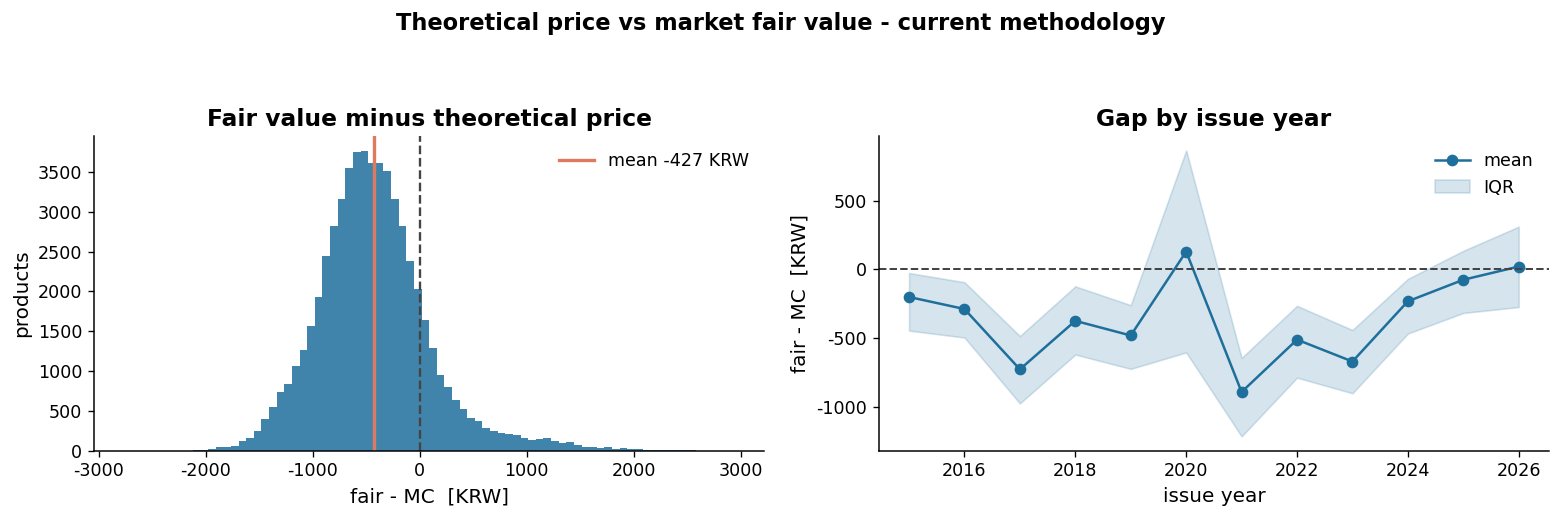

In [5]:
A = df[["item", "fair", "tenor", "isu_ord", "coupon", "B"]].copy()
A["mc_B"] = VAR.loc[A["item"].values, "mc_B"].values
A = A[np.isfinite(A.mc_B)]
A["err"] = (A.fair - A.mc_B) * FACE

print(f"전량 {len(A):,}건 | 공정가 − 이론가")
print(f"  편향 {A.err.mean():+.0f}원 | 중앙 {A.err.median():+.0f}원 "
      f"| MAE {A.err.abs().mean():.0f}원 | MAPE {(A.err.abs() / (A.fair * FACE)).mean() * 100:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.4))
ax[0].hist(A.err, bins=80, color=C_NEW, alpha=.85)
ax[0].axvline(0, color="#444", lw=1.4, ls="--")
ax[0].axvline(A.err.mean(), color=C_REF, lw=2, label=f"mean {A.err.mean():+.0f} KRW")
ax[0].set_xlabel("fair - MC  [KRW]"); ax[0].set_ylabel("products")
ax[0].set_title("Fair value minus theoretical price", fontweight="bold"); ax[0].legend(frameon=False)

yr = A.assign(y=(A.isu_ord // 365.25 + 1).astype(int)).groupby(
    pd.to_datetime([pd.Timestamp.fromordinal(int(o)) for o in A.isu_ord]).year)["err"]
ax[1].plot(yr.mean().index, yr.mean().values, "-o", color=C_NEW, label="mean")
ax[1].fill_between(yr.mean().index, yr.quantile(.25).values, yr.quantile(.75).values,
                   color=C_NEW, alpha=.18, label="IQR")
ax[1].axhline(0, color="#444", lw=1.2, ls="--")
ax[1].set_xlabel("issue year"); ax[1].set_ylabel("fair - MC  [KRW]")
ax[1].set_title("Gap by issue year", fontweight="bold"); ax[1].legend(frameon=False)
fig.suptitle("Theoretical price vs market fair value - current methodology",
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .93])
fig.savefig(fm.image("pricer_fair_gap"), dpi=200, bbox_inches="tight")
plt.show()

## 결론

1. **현행 방법론이 추적 패키지만으로 재현된다.** 1-2절에서 저장된 `mc_B` 와 비트 단위로 일치한다.
   `module.features`(변동성·상관) · `module.curve`(부트스트랩) · `module.dividend`(이산배당) ·
   `module.mc_engine`(엔진) 네 모듈이 전부다.
2. **경로 수는 정확도가 아니라 잡음을 정한다.** 1-3절의 표준오차가 대리모형 MAE 대비 몇 %인지가
   "모델을 더 키워서 얻을 수 있는 한계"를 정한다. 40,000 → 100,000 은 잡음을 약 0.63배로 줄인다.
3. **공정가와의 격차는 방법론의 실패가 아니다.** 이론가는 무차익 값이고, 그 격차(발행사 마진 · 유동성 ·
   헤지비용)를 설명하는 것은 2단계의 일이다. 1-4절은 그 격차가 발행연도에 따라 어떻게 움직이는지만 보인다.

**은퇴한 노트북과 그 결론** (이 노트북이 흡수)

| 종전 노트북 | 결론 | 채택 |
|---|---|---|
| 15 자문안 EWMA-120 | 변동성·상관 창을 6개월로 | O |
| 16 이산배당 | 이산과 연속이 사실상 동일, 배당 반영은 편향을 줄임 | O (이산) |
| 17 부트스트랩 커브 | NS 커브의 1~3년 과대평가를 교정 | O |
| 5 · 6 · 14 내재변동성 | 원자료 IV 는 ATM 단일 지점, 기간구조 없음 | X (미채택) |
| 18 변형 A vs B | B 채택 | O |
| 19 yfinance 배당 | LSEG 대조로 배당 자료 검증 | 참고 |